# TP3 - Procesamiento del Lenguaje Natural (NLP)
**Inteligencia Artificial y Neurociencias**

**Leoni, Petra - Mendez, Agustín - Pizi, Lucía - Siles, Milagros**

El objetivo de este trabajo práctico es experimentar con distintos enfoques de procesamiento del lenguaje natural para clasificar la postura de comentarios en español y comparar su desempeño predictivo, costo computacional y limitaciones.

Se evalúan tres enfoques principales:
- **Modelos clásicos de Machine Learning**, utilizando representaciones textuales.
- **Modelos preentrenados**, evaluados con y sin fine-tuning.
- **Large Language Models (LLMs)**, mediante estrategias de zero-shot y few-shot prompting.

La comparación buscará determinar en qué situaciones resulta conveniente utilizar cada enfoque, considerando tanto su desempeño como los recursos necesarios.

## 1. Exploración y preparación de datos

### 1.1. Instalación de dependencias

Se instalan e importan las librerías necesarias para cargar, manipular y visualizar los datos.

In [ ]:
!pip -q install datasets statsmodels

import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

SEED = 42
CLASES = ["favor", "against", "neutral"]   # orden fijo usado en todo el TP
sns.set_theme(style="whitegrid")

### 1.2. Carga y descripción del dataset

Se utiliza el dataset **ALIA Spanish Stance Detection**, compuesto por 3.000 comentarios en español sobre distintas propuestas ciudadanas.

Cada registro contiene la propuesta a la que responde el comentario (`target`), la descripción de esa propuesta (`description`), el texto del comentario (`comment`) y tres anotaciones humanas independientes que clasifican la postura como *favor*, *against* o *neutral*.

El dataset también proporciona una etiqueta mayoritaria (`majority_label`), obtenida a partir de las anotaciones individuales.

Cargamos los datos y exploramos su estructura inicial.

In [ ]:
dataset = load_dataset("SINAI/ALIA-es-discriminative-stance-detection")

df = dataset["train"].to_pandas()

print("Dimensiones:", df.shape)
display(df.head())

README.md:   0%|          | 0.00/20.1k [00:00<?, ?B/s]

corpus_stance_detection_ALIA.jsonl:   0%|          | 0.00/4.48M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3000 [00:00<?, ? examples/s]

Dimensiones: (3000, 8)


,id,target,description,comment,annotation_1,annotation_2,annotation_3,majority_label
0,1,"""Bajar"" las motos de las aceras.",Esta propuesta es originaria del vecino. [NOMB...,A mi no me molesta tanto que aparquen en la ac...,neutral,against,neutral,neutral
1,2,"""Bajar"" las motos de las aceras.",Esta propuesta es originaria del vecino. [NOMB...,Existe una ordenanza municipal que autoriza y ...,against,against,against,against
2,3,"""Bajar"" las motos de las aceras.","Los motoristas, aparte del ruido a veces intol...",Las motos son la solución para descongestionar...,against,neutral,favor,
3,4,"""Bajar"" las motos de las aceras.","Los motoristas, aparte del ruido a veces intol...",Aquí todo se soluciona con multas e impuestos....,neutral,against,against,against
4,5,ARREGLAR LOS REBAJES DE LOS BORDILLOS PARA FAC...,El mal estado de las calles y aceras ha hecho ...,La accesibilidad no es un concepto de patente ...,favor,favor,favor,favor


### 1.3. Distribución de clases

Analizamos la distribución de las etiquetas mayoritarias para identificar posibles desbalances entre las clases.

Este análisis es importante porque una distribución desigual puede favorecer a los modelos que predicen las categorías más frecuentes. Por este motivo, utilizaremos **Macro-F1** como métrica principal de evaluación, ya que pondera por igual el desempeño de cada clase.

También revisamos la presencia de valores faltantes en las distintas columnas del dataset.

Distribución de clases:
majority_label
favor      1780
against     627
neutral     443
            150
Name: count, dtype: int64

Valores faltantes:
id                0
target            0
description       0
comment           0
annotation_1      0
annotation_2      0
annotation_3      0
majority_label    0
dtype: int64


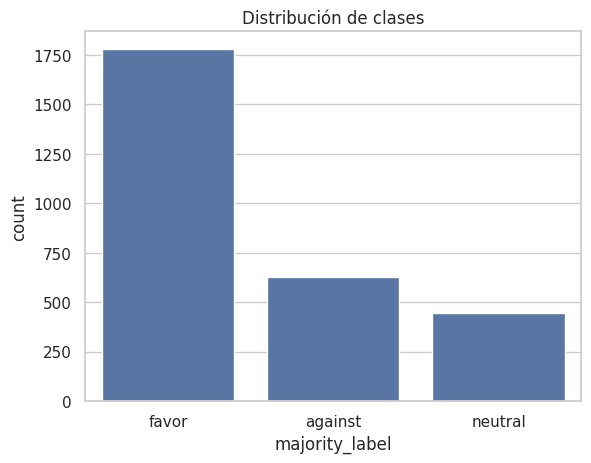

In [ ]:
print("Distribución de clases:")
print(df["majority_label"].value_counts(dropna=False))

print("\nValores faltantes:")
print(df.isna().sum())

sns.countplot(data=df, x="majority_label", order=CLASES)
plt.title("Distribución de clases")
plt.show()

**Observaciones**

Se observa un desbalance en la distribución de clases: la categoría *favor* (1.780 comentarios) es considerablemente más frecuente que *against* (627) y *neutral* (443).

Además, existen 150 registros (5% del dataset) con `majority_label` vacío. Estos casos corresponden a comentarios en los que los tres anotadores asignaron etiquetas diferentes.

Aunque ninguna de las columnas presenta valores nulos, esos registros son en la práctica datos faltantes de la variable objetivo y requieren un tratamiento particular.

### 1.4. Análisis de los textos

Antes de implementar los modelos, analizamos algunas características de los textos para comprender mejor el corpus y orientar las decisiones de preprocesamiento.

En particular, analizamos:
- La longitud de los comentarios, medida en palabras y caracteres, y sus diferencias entre clases.
- La propuesta (`target`) y su descripción (`description`): como la postura se define *respecto de una propuesta*, estos campos podrían ser parte de la entrada de los modelos.
- Ejemplos, vocabulario frecuente por clase y duplicados.

#### 1.4.1. Longitud de los comentarios

In [ ]:
df["num_palabras"] = df["comment"].str.split().str.len()
df["num_caracteres"] = df["comment"].str.len()

display(df[["num_palabras", "num_caracteres"]].describe())

,num_palabras,num_caracteres
count,3000.000000,3000.000000
mean,54.239667,312.591000
std,32.060883,183.408644
min,7.000000,79.000000
25%,28.000000,159.000000
50%,46.000000,266.000000
75%,76.000000,444.000000
max,155.000000,800.000000


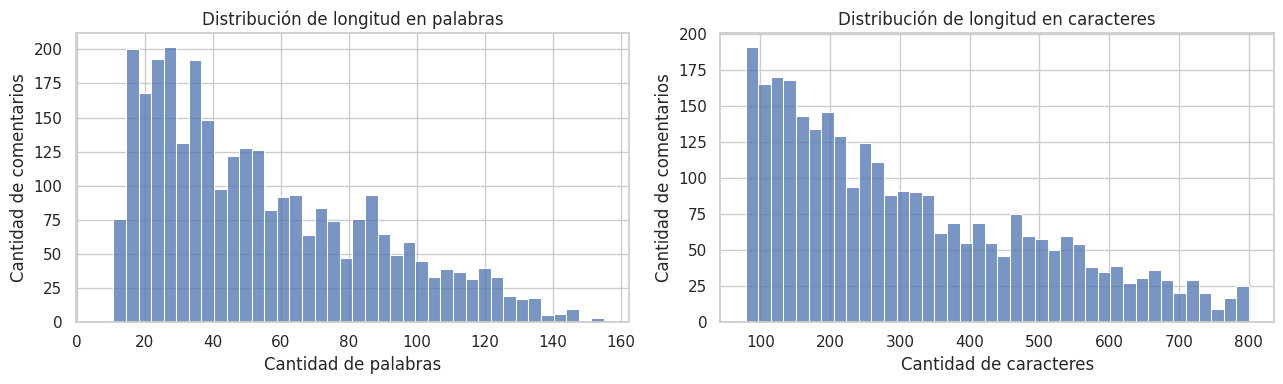

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=df, x="num_palabras", bins=40, ax=axes[0])
axes[0].set_title("Distribución de longitud en palabras")
axes[0].set_xlabel("Cantidad de palabras")
axes[0].set_ylabel("Cantidad de comentarios")

sns.histplot(data=df, x="num_caracteres", bins=40, ax=axes[1])
axes[1].set_title("Distribución de longitud en caracteres")
axes[1].set_xlabel("Cantidad de caracteres")
axes[1].set_ylabel("Cantidad de comentarios")

plt.tight_layout()
plt.show()

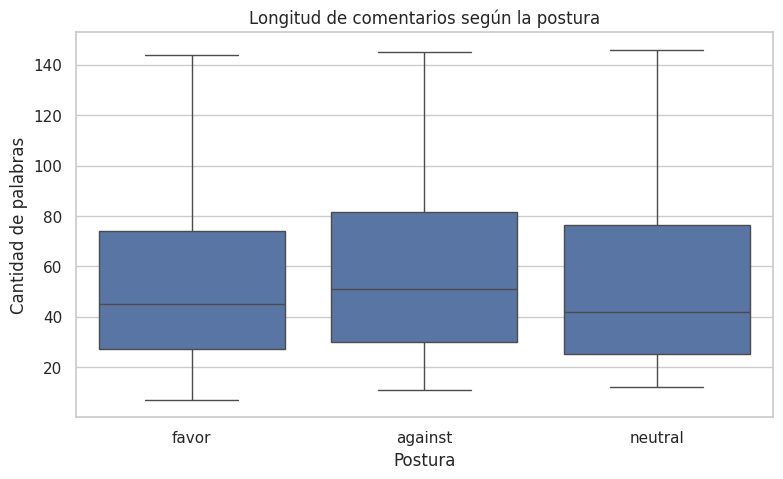

,count,mean,median,std
majority_label,,,,
against,627,57.72,51.0,32.13
favor,1780,53.29,45.0,31.96
neutral,443,52.46,42.0,32.14


In [ ]:
# Excluimos temporalmente los casos sin mayoría
df_etiquetados = df[df["majority_label"].isin(CLASES)].copy()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_etiquetados, x="majority_label", y="num_palabras",
            order=CLASES, showfliers=False)
plt.title("Longitud de comentarios según la postura")
plt.xlabel("Postura")
plt.ylabel("Cantidad de palabras")
plt.show()

display(
    df_etiquetados.groupby("majority_label")["num_palabras"]
    .agg(["count", "mean", "median", "std"]).round(2)
)

**Observaciones**

Los comentarios presentan una longitud promedio de 54 palabras y 313 caracteres, con medianas de 46 palabras y 266 caracteres, respectivamente. Las distribuciones muestran una asimetría positiva, con predominio de textos relativamente cortos (máximo: 155 palabras / 800 caracteres).

Al comparar las clases, se observa que los comentarios *against* son ligeramente más extensos (57,72 palabras en promedio) que los *favor* (53,29) y *neutral* (52,46). Sin embargo, las distribuciones presentan una superposición considerable, por lo que la longitud por sí sola no parece ser una característica suficientemente discriminativa para clasificar la postura.

Dado que ningún comentario supera las 155 palabras, longitudes máximas de secuencia moderadas deberían alcanzar para los modelos preentrenados.

#### 1.4.2. Propuesta (`target`) y descripción (`description`)

La postura de un comentario solo tiene sentido en relación con la propuesta que comenta. Por eso analizamos campos como su largo, cuántas propuestas distintas hay y cuántos comentarios recibe cada una. Esto último también es clave para diseñar correctamente el split de datos.

In [ ]:
df["num_palabras_target"] = df["target"].str.split().str.len()
df["num_palabras_description"] = df["description"].str.split().str.len()

display(df[["num_palabras_target", "num_palabras_description"]].describe().round(1))

print("Propuestas únicas (target):", df["target"].nunique())
print("Descripciones únicas:", df["description"].nunique())

print("\nComentarios por propuesta (target):")
display(df.groupby("target").size().describe().round(2))

print("Descripciones distintas por target:")
display(df.groupby("target")["description"].nunique().describe().round(2))

print("\nEjemplo de descripción:\n", df["description"].iloc[2][:600])

,num_palabras_target,num_palabras_description
count,3000.0,3000.0
mean,7.4,152.4
std,3.0,143.6
min,1.0,8.0
25%,5.0,62.0
50%,7.0,105.0
75%,10.0,190.0
max,16.0,944.0


Propuestas únicas (target): 387
Descripciones únicas: 424

Comentarios por propuesta (target):


,0
count,387.00
mean,7.75
std,9.76
min,3.00
25%,4.00
50%,4.00
75%,7.00
max,106.00


Descripciones distintas por target:


,description
count,387.00
mean,1.10
std,0.36
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,4.00



Ejemplo de descripción:
 Los motoristas, aparte del ruido a veces intolerable de sus motos,  circulan hoy día impunemente por las aceras de nuestra ciudad y aparcan en ellas donde mejor les parece hasta el punto de suponer un verdadero abuso sobre los viandantes, cuando no una agresión peligrosa. Todo ello se debe a la falta absoluta de ordenación y control de la movilidad de los medios de transporte en Madrid. Si realmente se quiere promocionar el uso de la moto  frente al coche, deben utilizarse el número plazas de estacionamientos de coches adecuado para convertirlas en aparcamientos de motos, y prohibir a éstas el


In [ ]:
# Marcas de anonimización tipo [NOMBRE] u otros textos entre corchetes
patron_anon = r"\[[A-ZÁÉÍÓÚÑ_ ]{3,}[^\]]*\]"
for col in ["target", "description", "comment"]:
    n = df[col].str.contains(patron_anon, regex=True).sum()
    print(f"{col}: {n} registros con marcas entre corchetes")

print(Counter(re.findall(patron_anon, " ".join(df["description"]))).most_common(5))

target: 0 registros con marcas entre corchetes
description: 6 registros con marcas entre corchetes
comment: 2 registros con marcas entre corchetes
[('[NOMBRE]', 6)]


**Observaciones**

El dataset contiene 387 propuestas distintas (`target`) y 424 descripciones distintas. La mayoría de las propuestas tiene una única descripción, pero algunas aparecen con hasta 4 descripciones diferentes bajo el mismo título.

La cantidad de comentarios por propuesta es muy desigual: la mediana es de 4 comentarios y el 75% de las propuestas tiene 7 o menos, pero algunas concentran muchísimos (máximo 106, *"Billete único para el transporte público"*). Esto tiene dos consecuencias para el split:

1. Los comentarios de una misma propuesta no deberían repartirse entre conjuntos.
2. Las propuestas muy grandes pueden dominar un conjunto de evaluación chico.

Los títulos son cortos (mediana de 7 palabras), mientras que las descripciones son mucho más largas que los comentarios (mediana de 105 palabras, máximo 944). Si se usa *propuesta + comentario* como entrada de un encoder, conviene usar solo el título, o truncar la descripción, porque con la descripción completa se superarían fácilmente los 512 tokens.

Las marcas de anonimización son muy escasas (`[NOMBRE]` aparece en 6 descripciones y en 2 comentarios), por lo que no requieren tratamiento especial.

#### 1.4.3. Ejemplos, vocabulario frecuente y duplicados

In [ ]:
for clase in CLASES:
    print(f"--- {clase.upper()} ---")
    for texto in df[df["majority_label"] == clase]["comment"].sample(2, random_state=SEED):
        print("•", texto[:300], "\n")

print("Comentarios duplicados:", df["comment"].duplicated().sum())
print("Duplicados (propuesta + comentario):", df.duplicated(["target", "comment"]).sum())

--- FAVOR ---
• 100% de acuerdo! La idea del campo del Moro me parece muy buena, ojalá fuera realizable!

Hace un tiempo se que pusieron autobuses que podían llevar bicis por fuera, a modo de maletero, creo que era el que conecta Príncipe Pío con el Zoo, y me pareció una tontería ponerlo en un recorrido que se pued 

• Es necesaria toda ayuda de difusión sobre las posibilidades y necesidad de adopción de animales, que por motivos ajenos a ellos se encuentran diariamente abandonados, necesidad de concienciar sobre la tenencia de cualquier animal doméstico, que no puede ser un capricho pasajero, que tienen necesidad 

--- AGAINST ---
• No estoy de acuerdo... pero por qué no entonces una tasa para los fumadores que tiran sus colillas y ensucian las calles, además de los que no ven las papeleras...  

• ATENCION: Revisar lo que ahora se vota. NO ES SER en todo el Barrio Pueblo Nuevo, ni en todo el Barrio Concepción, si en todo el Barrio San Juan Bautista. En Pueblo Nuevo solo una pequeña p

In [ ]:
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

stop_es = set(stopwords.words("spanish"))

def top_palabras(textos, n=12):
    c = Counter()
    for t in textos:
        c.update(w for w in re.findall(r"[a-záéíóúñü]+", t.lower())
                 if w not in stop_es and len(w) > 2)
    return c.most_common(n)

for clase in CLASES:
    palabras = top_palabras(df.loc[df["majority_label"] == clase, "comment"])
    print(f"{clase:8s}→ " + ", ".join(f"{w} ({n})" for w, n in palabras))

favor   → madrid (424), ser (275), propuesta (231), acuerdo (230), gente (217), parece (209), barrio (207), mas (205), ciudad (201), creo (200), ayuntamiento (197), hacer (162)
against → ser (116), madrid (103), gente (103), creo (102), propuesta (96), mas (86), parece (82), hacer (75), mejor (69), solo (68), zona (64), bien (63)
neutral → madrid (131), propuesta (60), ayuntamiento (59), ser (57), creo (55), zona (49), ciudad (48), mas (46), hacer (44), parece (44), bien (43), gente (37)


**Observaciones**

- **Duplicados:** hay 14 comentarios cuyo texto aparece más de una vez, pero nunca dentro de la misma propuesta. Son 9 textos genéricos copiados en varias propuestas (por ejemplo, *"Es imposible alcanzar los 27.662 apoyos necesarios…"* aparece en 6 propuestas distintas). Tres de esos textos tienen etiquetas distintas según la propuesta a la que responden: el mismo texto puede ser *favor* en una propuesta y *against* en otra. Esto confirma que la postura depende de la propuesta y no solo del comentario. Como son pocos casos, se conservan.

- **Vocabulario:** las palabras más frecuentes de las tres clases son prácticamente las mismas y son mayormente temáticas (*madrid*, *propuesta*, *ayuntamiento*, *gente*, *barrio*, *zona*) o verbos genéricos (*ser*, *creo*, *parece*, *hacer*). La única palabra con carga de postura clara en el top es *acuerdo* en *favor*. Es una señal de que los modelos de bolsa de palabras podrían aprender el tema y no la postura, y de que la información discriminativa está en expresiones menos frecuentes y en construcciones como *"(no) estoy de acuerdo"*, que unigramas sin negaciones no capturan bien.

- **Ejemplos:** la diferencia entre clases no siempre es evidente. Varios comentarios *neutral* son en realidad quejas sobre el proceso o la plataforma (no sobre la propuesta) y algunos *against* son aclaraciones sobre lo que se vota, lo que anticipa la dificultad de la clase *neutral*.

### 1.5. Acuerdo entre anotadores

Cada comentario fue clasificado de manera independiente por tres anotadores humanos. Para evaluar la consistencia de estas anotaciones, analizamos el nivel de acuerdo entre ellos.

Distinguimos tres situaciones:
- **Acuerdo total (3/3):** los tres anotadores asignan la misma etiqueta.
- **Acuerdo parcial (2/3):** dos anotadores coinciden y el tercero discrepa.
- **Sin mayoría (1/1/1):** cada anotador asigna una etiqueta diferente.

Este análisis permitirá identificar el grado de ambigüedad del dataset y fundamentar la elección de la variable objetivo.

In [ ]:
cols_anotadores = ["annotation_1", "annotation_2", "annotation_3"]

# Control: las anotaciones solo contienen las tres etiquetas esperadas
valores = set(df[cols_anotadores].stack().unique())
print("Valores en las anotaciones:", valores)
assert valores <= set(CLASES)

# Cantidad máxima de anotadores que coinciden
df["max_acuerdo"] = df[cols_anotadores].apply(lambda fila: fila.value_counts().max(), axis=1)

df["nivel_acuerdo"] = df["max_acuerdo"].map({
    3: "Total (3/3)",
    2: "Parcial (2/3)",
    1: "Sin mayoría (1/1/1)"
})

acuerdo = df["nivel_acuerdo"].value_counts()
display(pd.DataFrame({
    "Cantidad": acuerdo,
    "Porcentaje": (acuerdo / len(df) * 100).round(2)
}))

# Control: los casos sin mayoría son exactamente los que tienen majority_label vacío
print("Sin mayoría == majority_label vacío:",
      ((df["max_acuerdo"] == 1) == (~df["majority_label"].isin(CLASES))).all())

Valores en las anotaciones: {'favor', 'neutral', 'against'}


,Cantidad,Porcentaje
nivel_acuerdo,,
Total (3/3),1539,51.3
Parcial (2/3),1311,43.7
Sin mayoría (1/1/1),150,5.0


Sin mayoría == majority_label vacío: True


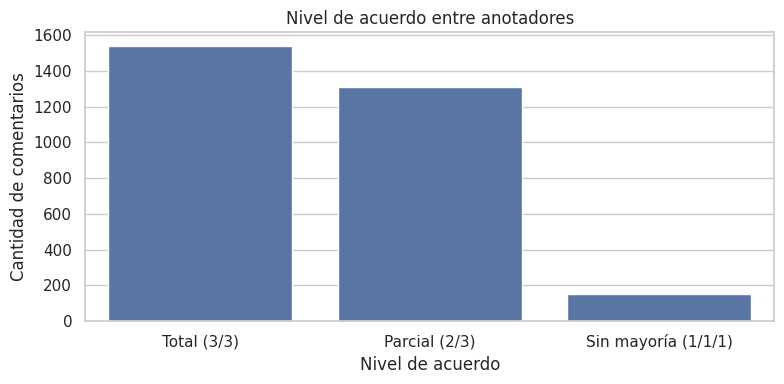

In [ ]:
orden = ["Total (3/3)", "Parcial (2/3)", "Sin mayoría (1/1/1)"]

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="nivel_acuerdo", order=orden)
plt.title("Nivel de acuerdo entre anotadores")
plt.xlabel("Nivel de acuerdo")
plt.ylabel("Cantidad de comentarios")
plt.tight_layout()
plt.show()

#### 1.5.1. ¿En qué clases y entre qué etiquetas hay desacuerdo?

Además del porcentaje global, nos interesa saber si algunas clases generan más desacuerdo que otras y qué etiquetas se confunden entre sí cuando hay acuerdo parcial.

In [ ]:
# Nivel de acuerdo según la clase mayoritaria
display((pd.crosstab(df_etiquetados["majority_label"],
                     df.loc[df_etiquetados.index, "nivel_acuerdo"],
                     normalize="index") * 100).round(1).loc[CLASES])

# En acuerdo parcial: etiqueta mayoritaria vs. etiqueta del anotador discrepante
def par_discrepancia(fila):
    vc = fila[cols_anotadores].value_counts()
    return f"{vc.index[0]} (mayoría) vs {vc.index[1]}"

parcial = df[df["max_acuerdo"] == 2]
display(parcial.apply(par_discrepancia, axis=1).value_counts().to_frame("Cantidad"))

nivel_acuerdo,Parcial (2/3),Total (3/3)
majority_label,,
favor,36.9,63.1
against,51.5,48.5
neutral,74.9,25.1


,Cantidad
favor (mayoría) vs neutral,418
favor (mayoría) vs against,238
neutral (mayoría) vs favor,229
against (mayoría) vs neutral,164
against (mayoría) vs favor,159
neutral (mayoría) vs against,103


#### 1.5.2. Coeficiente Fleiss' Kappa

Para complementar el análisis descriptivo, calculamos el coeficiente *Fleiss' Kappa*, que mide el grado de acuerdo entre múltiples anotadores, corrigiendo por la coincidencia esperada por azar. El coeficiente toma el valor 1 cuando existe acuerdo perfecto y 0 cuando el acuerdo equivale al esperado por azar y puede ser negativo cuando el acuerdo es inferior al esperado por azar.

In [ ]:
from statsmodels.stats.inter_rater import fleiss_kappa

# Cantidad de votos por clase para cada comentario
matriz_votos = pd.DataFrame({
    clase: (df[cols_anotadores] == clase).sum(axis=1) for clase in CLASES
})
assert (matriz_votos.sum(axis=1) == 3).all()   # cada comentario tiene exactamente 3 votos

kappa = fleiss_kappa(matriz_votos.to_numpy())
print(f"Fleiss' Kappa: {kappa:.4f}")

Fleiss' Kappa: 0.4060


**Observaciones**

El 51,3% de los comentarios presenta acuerdo total entre los tres anotadores, mientras que el 43,7% alcanza una mayoría de dos anotadores. El 5% restante no presenta una etiqueta mayoritaria. Es decir, el 48,7% de los comentarios tiene algún desacuerdo.

Se obtuvo un coeficiente *Fleiss' Kappa* de 0,4060. Según la escala, el rango 0,21–0,40 se considera acuerdo "aceptable" y 0,41–0,60 "moderado", por lo que el valor obtenido queda en el límite entre ambos: el acuerdo es moderado-bajo.

Esto muestra que la identificación de posturas tiene un componente importante de ambigüedad, especialmente en comentarios cuya intención no es explícita. Hay que considerarlo al definir la variable objetivo y al interpretar el desempeño de los modelos, ya que parte del error de cualquier modelo respecto del `majority_label` puede deberse a ruido en las etiquetas y no a limitaciones del modelo.

**Desacuerdo por clase:** el acuerdo depende mucho de la clase. Los comentarios con mayoría *favor* tienen acuerdo total en el 63,1% de los casos, *against* en el 48,5% y *neutral* apenas en el 25,1%, es decir que tres de cada cuatro comentarios *neutral* tienen al menos un anotador que opinó distinto. En los casos de acuerdo parcial, el par más frecuente es *favor (mayoría)* vs. *neutral* (418 casos), seguido de *favor* vs. *against* (238) y *neutral* (mayoría) vs. *favor* (229). Es decir, la frontera más difusa es entre *neutral* y *favor*. Dicho esto, es esperable que *neutral* sea la clase más difícil para todos los modelos, y que su F1 sea el que más baje el Macro-F1.

### 1.6. Definición de la variable objetivo

Para los experimentos principales utilizaremos la etiqueta mayoritaria (`majority_label`) como variable objetivo, considerando las tres clases: *favor*, *against* y *neutral*.

Evaluamos las siguientes alternativas:

- **Majority voting:** asigna a cada comentario la clase elegida por al menos dos de los tres anotadores. Permite formular el problema como una clasificación multiclase.
- **Soft labels:** representan la proporción de votos recibidos por cada clase. Por ejemplo, dos votos *favor* y uno *neutral* se representarían como `[2/3, 0, 1/3]`, en el orden *favor*, *against*, *neutral*. Conservan información sobre el desacuerdo, pero requieren adaptar el entrenamiento de los modelos.
- **Scores continuos:** permiten representar la postura en una escala numérica, aunque implican establecer una relación ordinal entre las clases y no capturan necesariamente la diferencia conceptual entre una postura neutral y una postura ambigua.

Decisión tomada: utilizamos **majority voting** por su simplicidad, interpretabilidad y compatibilidad con los enfoques de NLP que se comparan.

Los 150 comentarios sin mayoría serán excluidos de los experimentos principales (la métrica de evaluación se define respecto del `majority_label`, que en esos casos no existe), mientras que se conservarán los 2.850 comentarios restantes, incluyendo aquellos con acuerdo parcial.

Como las soft labels se calculan sin costo, se guardan igualmente en el dataframe (`soft_favor`, `soft_against`, `soft_neutral`) para poder usarlas como extensión durante el entrenamiento, siempre evaluando las predicciones finales contra `majority_label`.

*Limitación:* al excluir los casos sin mayoría, los resultados no son extrapolables a los comentarios más ambiguos del dataset.

In [ ]:
df_modelado = df[df["majority_label"].isin(CLASES)].copy().reset_index(drop=True)

df_modelado["label"] = df_modelado["majority_label"]
label2id = {c: i for i, c in enumerate(CLASES)}
id2label = {i: c for c, i in label2id.items()}
df_modelado["label_id"] = df_modelado["label"].map(label2id)

# Soft labels (proporción de votos por clase)
for c in CLASES:
    df_modelado[f"soft_{c}"] = (df_modelado[cols_anotadores] == c).sum(axis=1) / 3

# Control: la etiqueta mayoritaria coincide con la clase más votada
mas_votada = df_modelado[[f"soft_{c}" for c in CLASES]].idxmax(axis=1).str.replace("soft_", "")
print("majority_label == clase más votada:", (mas_votada == df_modelado["label"]).mean())

print("\nComentarios originales:", len(df))
print("Comentarios para modelado:", len(df_modelado))
print("Comentarios excluidos:", len(df) - len(df_modelado))
display(df_modelado["label"].value_counts())

majority_label == clase más votada: 1.0

Comentarios originales: 3000
Comentarios para modelado: 2850
Comentarios excluidos: 150


,count
label,
favor,1780
against,627
neutral,443


### 1.7. Preprocesamiento: exploración y plan

La consigna pide considerar técnicas de preprocesamiento (tokenización, lematización, eliminación de stopwords, normalización) y evaluar su utilidad. Acá analizamos las características del texto que motivan cada decisión. El efecto sobre el desempeño se medirá en la sección de modelos clásicos y se comparará con el uso de modelos preentrenados, que traen su propio tokenizador.

In [ ]:
# Características "ruidosas" del texto
patrones = {
    "URLs": r"https?://|www\.",
    "Palabras en MAYÚSCULAS (≥3 letras)": r"\b[A-ZÁÉÍÓÚÑ]{3,}\b",
    "Signos ! ? ¡ ¿": r"[!?¡¿]",
    "Números": r"\d",
    "Emojis / símbolos": r"[\U0001F300-\U0001FAFF\u2600-\u27BF]",
}
display(pd.Series({k: df["comment"].str.contains(p, regex=True).mean() * 100
                    for k, p in patrones.items()}).round(1).to_frame("% de comentarios"))

# Tamaño del vocabulario según el nivel de normalización
def sin_acentos(t):
    return "".join(ch for ch in unicodedata.normalize("NFD", t) if unicodedata.category(ch) != "Mn")

variantes = {
    "Texto original": lambda t: t,
    "Minúsculas": lambda t: t.lower(),
    "Minúsculas + sin acentos": lambda t: sin_acentos(t.lower()),
}
vocab = {}
for nombre, f in variantes.items():
    v = set()
    for t in df["comment"]:
        v.update(re.findall(r"\w+", f(t)))
    vocab[nombre] = len(v)
display(pd.Series(vocab).to_frame("Tamaño del vocabulario"))

# Stopwords: ¿se llevan palabras relevantes para la postura?
negaciones = {"no", "ni", "sin", "nunca", "tampoco", "nada", "ningún", "ninguna", "ninguno"}
print("Negaciones incluidas en la lista de stopwords:", sorted(negaciones & stop_es))

,% de comentarios
URLs,0.1
Palabras en MAYÚSCULAS (≥3 letras),16.9
Signos ! ? ¡ ¿,22.9
Números,22.4
Emojis / símbolos,0.0


,Tamaño del vocabulario
Texto original,17952
Minúsculas,15702
Minúsculas + sin acentos,15108


Negaciones incluidas en la lista de stopwords: ['nada', 'ni', 'no', 'sin']


**Decisiones y plan de experimentos**

- **Tokenización y normalización:** se probará pasar a minúsculas y, como variante, quitar acentos (puede unificar comentarios escritos con y sin tildes, a costa de fusionar palabras distintas). Para los modelos preentrenados se usará el tokenizador propio de cada modelo, sin preprocesamiento agresivo (preservar el texto original suele ser lo recomendable en encoders).
- **Stopwords:** las listas estándar en español incluyen negaciones (*no*, *ni*, *sin*, *nunca*...) que pueden ser clave para detectar postura, así que se comparará eliminar las stopwords completas contra eliminarlas conservando las negaciones.
- **Lematización:** se evaluará como variante en los modelos clásicos (por ejemplo con spaCy `es_core_news_sm`), considerando su costo de cómputo.
- **N-gramas:** se probarán unigramas vs. uni+bigramas, ya que las construcciones con negación ("no es bueno") dependen del orden.

El texto es relativamente "limpio": casi no hay URLs (0,1%) ni emojis (0%). Un 16,9% de los comentarios tiene palabras en mayúsculas sostenidas (por ejemplo, *"NO SE PUEDE HACER"*), que pueden expresar énfasis o postura, un 22,9% tiene signos de exclamación o interrogación y un 22,4% contiene números. Pasar a minúsculas reduce el vocabulario de 17.952 a 15.702 términos (−12,5%) y quitar además los acentos lo lleva a 15.108 (−3,8% adicional). La ganancia de quitar acentos es chica, así que se probará solo como variante. La lista de stopwords de NLTK incluye *no*, *ni*, *sin* y *nada*, por lo que eliminarlas sin más borraría negaciones relevantes para la postura.

### 1.8. División de los datos

El dataset se dividirá en tres conjuntos de aproximadamente 70% (entrenamiento), 15% (validación) y 15% (test). El conjunto de entrenamiento se usa para ajustar los modelos, el de validación para seleccionar configuraciones e hiperparámetros y el de test exclusivamente para la evaluación final. Se usa una semilla fija para asegurar la reproducibilidad.

#### El problema del split aleatorio

Como vimos anteriormente, cada propuesta recibe en promedio varios comentarios (con casos de más de 100). Si los datos se dividen al azar, comentarios de una misma propuesta quedan repartidos entre train y test, y los modelos pueden aprovechar vocabulario, tema y sesgos propios de la propuesta en lugar de aprender a detectar postura en general. Eso infla las métricas de test.

Lo verificamos primero con un split aleatorio estratificado:

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

# Split aleatorio estratificado (solo para diagnóstico, NO se usa en los experimentos)
tr_a, tmp_a = train_test_split(df_modelado, test_size=0.30, random_state=SEED,
                               stratify=df_modelado["label"])
_, te_a = train_test_split(tmp_a, test_size=0.50, random_state=SEED, stratify=tmp_a["label"])

solapadas = set(te_a["target"]) & set(tr_a["target"])
print(f"Propuestas de test que también están en train: {len(solapadas)} de {te_a['target'].nunique()}")
print(f"Comentarios de test cuya propuesta está en train: {te_a['target'].isin(tr_a['target']).mean():.1%}")

Propuestas de test que también están en train: 224 de 226
Comentarios de test cuya propuesta está en train: 99.3%


Prácticamente todas las propuestas de test (224 de 226) también aparecen en train. Por eso se utiliza un **split agrupado por propuesta** (`target`), donde todos los comentarios de una misma propuesta quedan en el mismo conjunto, de modo que el test mide la capacidad de generalizar a propuestas nuevas, que es el escenario realista.

#### Propuestas muy grandes

Agrupar no alcanza, porque el tamaño de los grupos es muy desigual (mediana de 4 comentarios, pero 15 propuestas con más de 25 y una con 103). En una primera versión del split, la propuesta *"Billete único para el transporte público"* (103 comentarios) cayó en test y representaba el 25% del conjunto de test; en validación, una sola propuesta aportaba el 12%. Así, el Macro-F1 de test terminaba midiendo en buena parte el desempeño sobre una única propuesta.

Para evitarlo:
1. Las propuestas con más de `UMBRAL_GRANDES = 25` comentarios se asignan siempre a train (aportan muchos ejemplos para aprender, pero dominarían cualquier conjunto de evaluación).
2. El resto de las propuestas se reparte con `StratifiedGroupKFold` en 5 folds (≈15% del total cada uno): un fold para test, uno para validación y los otros tres van a train (≈70/15/15 en total).
3. Como la estratificación con grupos es solo aproximada, se prueban varias semillas y se elige la que deja las proporciones de clase y el tamaño de validación y test más cercanos a lo buscado. Esta selección usa únicamente la distribución de etiquetas, sin entrenar ningún modelo, por lo que no filtra información del test.

In [ ]:
UMBRAL_GRANDES = 25      # propuestas con más comentarios que esto van siempre a train
N_SPLITS = 5             # folds sobre el resto de las propuestas (≈15% del total cada uno)

coms_por_propuesta = df_modelado.groupby("target").size()
propuestas_grandes = coms_por_propuesta[coms_por_propuesta > UMBRAL_GRANDES].index
es_grande = df_modelado["target"].isin(propuestas_grandes)
resto = df_modelado[~es_grande]
print(f"Propuestas grandes (> {UMBRAL_GRANDES} comentarios): {len(propuestas_grandes)} "
      f"→ {es_grande.sum()} comentarios fijos en train")

prop_global = df_modelado["label"].value_counts(normalize=True)

def evaluar_semilla(seed):
    sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
    folds = [resto.index[idx] for _, idx in sgkf.split(resto, resto["label"], groups=resto["target"])]
    score = 0
    for f in folds[:2]:   # folds 0 (test) y 1 (validación)
        p = df_modelado.loc[f, "label"].value_counts(normalize=True).reindex(prop_global.index).fillna(0)
        score += (p - prop_global).abs().sum() + abs(len(f) / len(df_modelado) - 0.15)
    return score, seed, folds

score, seed_split, folds = min((evaluar_semilla(s) for s in range(300)), key=lambda x: x[0])
print(f"Semilla elegida: {seed_split} (desvío total: {score:.4f})")

idx_test = folds[0]
idx_val = folds[1]

df_modelado["split"] = "train"
df_modelado.loc[idx_val, "split"] = "val"
df_modelado.loc[idx_test, "split"] = "test"

train_df = df_modelado[df_modelado["split"] == "train"].copy()
val_df = df_modelado[df_modelado["split"] == "val"].copy()
test_df = df_modelado[df_modelado["split"] == "test"].copy()

for nombre, d in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{nombre:10s}: {len(d):5d} comentarios ({len(d)/len(df_modelado):.1%}) | "
          f"{d['target'].nunique()} propuestas | propuesta más grande: "
          f"{d.groupby('target').size().max()} ({d.groupby('target').size().max()/len(d):.1%})")

Propuestas grandes (> 25 comentarios): 15 → 691 comentarios fijos en train
Semilla elegida: 140 (desvío total: 0.0466)
Train     :  2019 comentarios (70.8%) | 242 propuestas | propuesta más grande: 103 (5.1%)
Validation:   413 comentarios (14.5%) | 75 propuestas | propuesta más grande: 21 (5.1%)
Test      :   418 comentarios (14.7%) | 70 propuestas | propuesta más grande: 19 (4.5%)


In [ ]:
# Verificaciones: ninguna propuesta compartida entre conjuntos
for a, b, n in [(train_df, val_df, "train-val"), (train_df, test_df, "train-test"), (val_df, test_df, "val-test")]:
    assert not set(a["target"]) & set(b["target"]), f"Fuga de propuestas en {n}"
print("OK: ninguna propuesta aparece en más de un conjunto.")

# Descripciones compartidas entre conjuntos (por si una misma propuesta tuviera otro título)
for a, b, n in [(train_df, val_df, "train-val"), (train_df, test_df, "train-test"), (val_df, test_df, "val-test")]:
    print(f"Descripciones compartidas {n}:", len(set(a["description"]) & set(b["description"])))

# Distribución de clases por conjunto
display((pd.DataFrame({
    "Train": train_df["label"].value_counts(normalize=True),
    "Validation": val_df["label"].value_counts(normalize=True),
    "Test": test_df["label"].value_counts(normalize=True),
}) * 100).round(2))

# Comentarios con texto idéntico (publicados en varias propuestas) repartidos entre conjuntos
dup = df_modelado[df_modelado["comment"].duplicated(keep=False)]
print("Textos duplicados presentes en más de un conjunto:",
      (dup.groupby("comment")["split"].nunique() > 1).sum(), "de", dup["comment"].nunique())

display(pd.crosstab(df_modelado["split"], df_modelado["label"]).loc[["train", "val", "test"], CLASES])

OK: ninguna propuesta aparece en más de un conjunto.
Descripciones compartidas train-val: 0
Descripciones compartidas train-test: 0
Descripciones compartidas val-test: 0


,Train,Validation,Test
label,,,
favor,62.51,63.20,61.48
against,22.04,21.07,22.73
neutral,15.45,15.74,15.79


Textos duplicados presentes en más de un conjunto: 4 de 9


label,favor,against,neutral
split,,,
train,1262,445,312
val,261,87,65
test,257,95,66


In [ ]:
# Guardamos la partición para que todo el grupo (y las demás partes del TP) usen exactamente los mismos conjuntos
df_modelado[["id", "split"]].to_csv("splits_tp3.csv", index=False)

**Observaciones**

El split final queda en 2.019 / 413 / 418 comentarios (70,8% / 14,5% / 14,7%), con 242, 75 y 70 propuestas respectivamente. Ninguna propuesta ni descripción se comparte entre conjuntos, y en validación y test la propuesta más grande representa solo el 4,5–5% del conjunto (antes de forzar las propuestas grandes a train, una sola propuesta era el 25% del test).

Las proporciones de clase quedan muy cercanas a las globales (diferencias de a lo sumo ≈1,7 puntos: validación tiene 21,1% de *against* y test 61,5% de *favor*, contra 22% y 62,5% globales). Agrupar por propuesta impide que sean idénticas, pero el test resulta una estimación más honesta del desempeño en propuestas no vistas. Es esperable que los resultados sean algo peores que con un split aleatorio.

Quedan 65 comentarios *neutral* en validación y 66 en test. Con tan pocos ejemplos, el F1 de *neutral* (y por lo tanto el Macro-F1) tiene bastante varianza, y diferencias pequeñas entre modelos (de 1–2 puntos) no deberían sobreinterpretarse.

*Limitaciones:* 4 de los 9 textos duplicados (comentarios genéricos copiados en varias propuestas) quedan en más de un conjunto. Como son pocos y en varios casos tienen etiquetas distintas según la propuesta, el efecto sobre las métricas es despreciable. Además, propuestas de temas muy parecidos pueden quedar en conjuntos distintos (por ejemplo, varias sobre transporte público), lo que un split por `target` no puede detectar.